## <b>[Github Link](https://github.com/VitorTavares-cct/CA-Machine-Learning)</b>

In [64]:
import nflreadpy as nfl

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, MinMaxScaler, StandardScaler, RobustScaler, Normalizer
from sklearn.decomposition import PCA


In [65]:
pbp = nfl.load_pbp([2023, 2024, 2025]).to_pandas()
ftn = nfl.load_ftn_charting([2023,2024,2025]).to_pandas()
ptcp = nfl.load_participation([2023,2024,2025]).to_pandas()

print(list(pbp.columns))
print(list(ftn.columns))
print(list(ptcp.columns))

['play_id', 'game_id', 'old_game_id', 'home_team', 'away_team', 'season_type', 'week', 'posteam', 'posteam_type', 'defteam', 'side_of_field', 'yardline_100', 'game_date', 'quarter_seconds_remaining', 'half_seconds_remaining', 'game_seconds_remaining', 'game_half', 'quarter_end', 'drive', 'sp', 'qtr', 'down', 'goal_to_go', 'time', 'yrdln', 'ydstogo', 'ydsnet', 'desc', 'play_type', 'yards_gained', 'shotgun', 'no_huddle', 'qb_dropback', 'qb_kneel', 'qb_spike', 'qb_scramble', 'pass_length', 'pass_location', 'air_yards', 'yards_after_catch', 'run_location', 'run_gap', 'field_goal_result', 'kick_distance', 'extra_point_result', 'two_point_conv_result', 'home_timeouts_remaining', 'away_timeouts_remaining', 'timeout', 'timeout_team', 'td_team', 'td_player_name', 'td_player_id', 'posteam_timeouts_remaining', 'defteam_timeouts_remaining', 'total_home_score', 'total_away_score', 'posteam_score', 'defteam_score', 'score_differential', 'posteam_score_post', 'defteam_score_post', 'score_differential

# Extraction

## About the Dataset
The dataset used for the Continuous Assessment is provenient from <b>nflreadpy</b> API, which provides NFL games statistics. From the multiple endpoints avialable, <b>load_pbp</b> (play by play), <b>ftn_charting</b> and <b>load_participation()</b> were selected, collecting data from every single play.

The following analysis will be based on <b>NFL Seasons</b> from 2023 to 2025 seasons.

Check [API Reference](https://nflreadpy.nflverse.com/api/load_functions/#nflreadpy.load_pbp) for more details.

## Columns Selected

### <b>load_pbp()</b>
#### Features Extracted
- game_id (str): NFL game id describing year, game number, away team and home team.
- qtr (int): Quarter which row happened, from 1 to 4 for regular period and 5 for overtime.
- down (int): Down from the play, from 1 to 4.
- ydstogo (int): Amount of yards to first down.
- play_type (enum): Type of play between run or pass.
- yards_gained (int): Amount of yards gained on play.
- yardline_100 (int): Total yards until defensive endzone.
- epa (float): Expected Points Added, a metric created by the NFL to measure the value of a play in the probability to score.
- success (bool): Success indicates if epa was positive (1) or if epa was negative (0).
- score_differential (int): Offensive Team Score - Defensive Team Score on the play.
- td_prob (float): Probability of Touchdown on drive.
- wp (float): Win Probability for the offensive team.
- air_yards (int): Amount of yards which the ball travelled until hits the receiver.
- interception (bool): If the result of the play was a defensive interception, the value is going to be 1, otherwise it is going to be 0.
- fumble_lost (bool): If the result of the play was the offense losing the ball possesion through a fumble, the value is going to be 1, otherwise it is going to be 0.
- qb_kneel (bool): If the QB took a knee on the play, the value is going to be 1, otherwise is going to be 0.
- qb_spike (bool): If the QB throw the ball on the ground to stop the clock is going to be 1, otherwise is going to be 0.
- incomplete_pass (bool): If the pass was incompleted, the value is going to be 1, otherwise is going to be 0.
- sack (bool): If the pass atempt ended as a QB Sacked, the value is going to be 1, otherwise is going to be 0.

#### Created Features
- score_situation (enum): Winning whenever the score_differential is negative (since the offense is losing), Tied whenever is 0 and Losing whenever the score_differential is positive.
- play_result (enum): Categorize positive run and pass plays, while pass plays the air_yards it is taken in consideration, instead of yards_gained, since it can mislead the type of pass because players can gain yards after catch.
- turnover (bool): True whenever the play ended in fumble lost or interception (not including tornover on downs).

### <b>load_ftn_charting()</b>

#### Features Extracted

### <b>load_participation</b>

#### Features Extracted

In [66]:
ptcp.head()

,nflverse_game_id,old_game_id,play_id,possession_team,offense_formation,offense_personnel,defenders_in_box,defense_personnel,number_of_pass_rushers,players_on_play,...,was_pressure,route,defense_man_zone_type,defense_coverage_type,offense_names,defense_names,offense_positions,defense_positions,offense_numbers,defense_numbers
0,2023_01_ARI_WAS,2023091007,39.0,WAS,None,"2 CB, 2 DE, 1 FS, 2 MLB, 1 OLB, 2 RB, 1 TE",0.0,"4 CB, 2 ILB, 1 K, 2 OLB, 1 SS, 1 WR",0.0,00-0032933;00-0034623;00-0035150;00-0037747;00...,...,False,,,None,Christian Holmes;Jartavius Martin;Casey Toohil...,Antonio Hamilton;Andre Chachere;Kris Boyd;Chri...,CB;CB;DE;DE;FS;MLB;MLB;OLB;RB;RB;TE,CB;CB;CB;CB;ILB;ILB;K;OLB;OLB;SS;WR,34;20;95;50;39;51;47;52;24;23;87,33;36;29;35;47;51;5;52;43;22;0
1,2023_01_ARI_WAS,2023091007,55.0,WAS,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 2 TE, 2 WR",6.0,"2 CB, 2 DE, 1 DT, 1 FS, 2 ILB, 2 OLB, 1 SS",0.0,00-0034445;00-0036884;00-0038984;00-0035636;00...,...,False,,,None,Nick Gates;Andrew Wylie;Sam Howell;Brian Robin...,Marco Wilson;Kei'Trel Clark;L.J. Collier;Jonat...,C;G;QB;RB;T;T;T;TE;TE;WR;WR,CB;CB;DE;DE;DT;FS;ILB;ILB;OLB;OLB;SS,63;71;14;8;72;77;76;82;87;17;1,20;13;91;93;95;34;7;10;25;52;3
2,2023_01_ARI_WAS,2023091007,77.0,WAS,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",5.0,"2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS",4.0,00-0034445;00-0036884;00-0038984;00-0035636;00...,...,False,HITCH/CURL,ZONE_COVERAGE,COVER_3,Nick Gates;Andrew Wylie;Sam Howell;Brian Robin...,Marco Wilson;Kei'Trel Clark;L.J. Collier;Jonat...,C;G;QB;RB;T;T;T;TE;WR;WR;WR,CB;CB;DE;DE;FS;ILB;ILB;OLB;OLB;SS;SS,63;71;14;8;72;77;76;82;4;17;1,20;13;91;93;34;7;10;25;97;3;22
3,2023_01_ARI_WAS,2023091007,102.0,WAS,UNDER CENTER,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",6.0,"2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS",0.0,00-0034445;00-0036884;00-0038984;00-0035636;00...,...,False,,,None,Nick Gates;Andrew Wylie;Sam Howell;Chris Rodri...,Marco Wilson;Kei'Trel Clark;L.J. Collier;Jonat...,C;G;QB;RB;T;T;T;TE;WR;WR;WR,CB;CB;DE;DE;FS;ILB;ILB;OLB;OLB;SS;SS,63;71;14;23;72;77;76;82;4;17;1,20;13;91;93;34;7;10;25;97;3;22
4,2023_01_ARI_WAS,2023091007,124.0,WAS,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",5.0,"2 CB, 2 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS",4.0,00-0034445;00-0036884;00-0038984;00-0035636;00...,...,False,IN/DIG,ZONE_COVERAGE,COVER_4,Nick Gates;Andrew Wylie;Sam Howell;Brian Robin...,Marco Wilson;Kei'Trel Clark;L.J. Collier;Jonat...,C;G;QB;RB;T;T;T;TE;WR;WR;WR,CB;CB;DE;DE;DT;FS;ILB;OLB;OLB;SS;SS,63;71;14;8;72;77;76;82;4;17;1,20;13;91;93;95;34;7;45;25;3;22


In [67]:
defensive_plays = pbp[
    (pbp["play_type"].isin(["pass", "run"]))
    & (pbp["down"].notna())
].copy()

# FTN Columns
ftn_cols = [
    "nflverse_game_id", "nflverse_play_id", "qb_location",
    "n_offense_backfield", "n_blitzers", "n_pass_rushers",
    "is_motion", "is_play_action", "is_screen_pass",
    "is_rpo", "is_trick_play", "is_qb_out_of_pocket",
    "read_thrown"
]

ftn = ftn[ftn_cols]
ftn = ftn.rename(columns={"nflverse_game_id": "game_id",
                       "nflverse_play_id": "play_id"})

# Participation Columns
ptcp_cols = [
    "nflverse_game_id", "play_id", "offense_formation",
    "offense_personnel", "defenders_in_box", "defense_personnel",
    "was_pressure", "defense_man_zone_type", "defense_coverage_type",
    "time_to_throw"
]

ptcp = ptcp[ptcp_cols]
ptcp = ptcp.rename(columns={"nflverse_game_id": "game_id"})

In [ ]:
sample_cols = [
    "game_id", "play_id", "qtr", "down", "defteam", "ydstogo", "yardline_100",
    "play_type", "yards_gained", "epa", "success", "score_differential",
    "td_prob", "wp", "air_yards", "interception", "fumble_lost",
    "qb_kneel", "qb_spike", "incomplete_pass", "sack", "qb_hit", "qb_dropback"
]

#Creating new categorical column
def score_situation(score_diff):
    if score_diff < 0:
        return "Winning"
    elif score_diff == 0:
        return "Tied"
    elif score_diff > 0:
        return "Losing"
    else:
        return "Unknown"

def play_result(play_type, yards_gained, air_yards, incomplete_pass, fumble, interception, sack):
    if fumble == 1:
        return "Fumble"
    elif interception == 1:
        return "Interception"
    elif sack == 1:
        return "Sack"
    elif play_type == "pass" and incomplete_pass == 1:
        return "Incomplete Pass"
    elif play_type == "pass" and yards_gained < 0:
        return "Negative Pass"
    elif play_type == "pass" and yards_gained > 0 and 0 < air_yards <= 10:
        return "Short Pass"
    elif play_type == "pass" and yards_gained > 0 and 10 < air_yards <= 20:
        return "Medium Pass"
    elif play_type == "pass" and yards_gained > 0 and air_yards > 20:
        return "Long Pass"
    elif play_type == "run" and yards_gained < 0:
        return "Tackle for Loss"
    elif play_type == "run" and  0 <= yards_gained <= 5:
        return "Short Run"
    elif play_type == "run" and 5 < yards_gained <= 10:
        return "Mid-range Run"
    elif play_type == "run" and 10 < yards_gained:
        return "Long Run"
    else:
        return "Other"

defensive_plays = defensive_plays[sample_cols]

defensive_plays["score_situation"] = defensive_plays["score_differential"].apply(score_situation)
defensive_plays["play_result"] = defensive_plays.apply(lambda df: play_result(df["play_type"], df["yards_gained"], df["air_yards"], df['incomplete_pass'], df['fumble_lost'], df['interception'], df['sack']), axis=1)
defensive_plays["turnover"] = ((defensive_plays["interception"] == 1) | (defensive_plays["fumble_lost"] == 1)).astype(int)
defensive_plays["year"] = defensive_plays["game_id"].str[0:4].astype(int)
defensive_plays["is_blitz"] = defensive_plays["n_blitzers"] > 0

# Merging Complementary Data
defensive_plays = pd.merge(defensive_plays, ftn, how="left", on=["game_id","play_id"])
defensive_plays = pd.merge(defensive_plays, ptcp, how="left", on=["game_id","play_id"])

# Creating a Colts subset
colts_defensive_plays = defensive_plays[defensive_plays['defteam'] == "IND"]

# Creating a subset without Colts
without_colts_defensive_plays = defensive_plays[defensive_plays['defteam'] != "IND"]

In [69]:
without_colts_defensive_plays.head()

,game_id,play_id,qtr,down,defteam,ydstogo,yardline_100,play_type,yards_gained,epa,...,is_qb_out_of_pocket,read_thrown,offense_formation,offense_personnel,defenders_in_box,defense_personnel,was_pressure,defense_man_zone_type,defense_coverage_type,time_to_throw
0,2023_01_ARI_WAS,55.0,1.0,1.0,ARI,10.0,75.0,run,3.0,-0.336103,...,False,0,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 2 TE, 2 WR",6.0,"2 CB, 2 DE, 1 DT, 1 FS, 2 ILB, 2 OLB, 1 SS",False,,None,NaN
1,2023_01_ARI_WAS,77.0,1.0,2.0,ARI,7.0,72.0,pass,6.0,0.703308,...,False,1,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",5.0,"2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS",False,ZONE_COVERAGE,COVER_3,1.9
2,2023_01_ARI_WAS,102.0,1.0,3.0,ARI,1.0,66.0,run,2.0,0.469799,...,False,0,UNDER CENTER,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",6.0,"2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS",False,,None,NaN
3,2023_01_ARI_WAS,124.0,1.0,1.0,ARI,10.0,64.0,pass,0.0,-0.521544,...,False,1,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",5.0,"2 CB, 2 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS",False,ZONE_COVERAGE,COVER_4,2.5
4,2023_01_ARI_WAS,147.0,1.0,2.0,ARI,10.0,64.0,pass,12.0,1.173155,...,False,2,UNDER CENTER,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",6.0,"2 CB, 2 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS",False,ZONE_COVERAGE,COVER_4,3.6


In [70]:
colts_defensive_plays.columns

Index(['game_id', 'play_id', 'qtr', 'down', 'defteam', 'ydstogo',
       'yardline_100', 'play_type', 'yards_gained', 'epa', 'success',
       'score_differential', 'td_prob', 'wp', 'air_yards', 'interception',
       'fumble_lost', 'qb_kneel', 'qb_spike', 'incomplete_pass', 'sack',
       'score_situation', 'play_result', 'turnover', 'year', 'qb_location',
       'n_offense_backfield', 'n_blitzers', 'n_pass_rushers', 'is_motion',
       'is_play_action', 'is_screen_pass', 'is_rpo', 'is_trick_play',
       'is_qb_out_of_pocket', 'read_thrown', 'offense_formation',
       'offense_personnel', 'defenders_in_box', 'defense_personnel',
       'was_pressure', 'defense_man_zone_type', 'defense_coverage_type',
       'time_to_throw'],
      dtype='object')

In [71]:
colts_defensive_plays['play_result'].value_counts()

play_result
Short Run          915
Short Pass         617
Incomplete Pass    537
Mid-range Run      259
Other              235
Medium Pass        183
Long Run           141
Tackle for Loss    137
Sack               115
Long Pass           67
Interception        45
Negative Pass       38
Fumble              25
Name: count, dtype: int64

## Data Cleaning

`air_yards`: 1587 plays have null values, which is expected, since every run will have null `air_yards` values.

`defense_coverage_type`: It is expected in most of run plays, however there are improvised plays which the cover can be identified.

`n_offense_backfield`: there are no situations of expected NaN for this feature, if it is further relevant for models, NaN rows are going to be dropped.

`n_pass_rushers`: there are no situations of expected NaN for this feature, if it is further relevant for models, NaN rows are going to be dropped.

### Removing Plays
In NFL, there are plays which the intention of executing it is just manage the clock. A Spike is when a offense throw the ball on the ground to stop the clock, preserving it, and a Kneel is when a offense take a knee to kill time. Both type of plays are going to be removed, since there is no intention on gaining yards.

In [72]:
colts_defensive_plays.isnull().sum()

game_id                     0
play_id                     0
qtr                         0
down                        0
defteam                     0
ydstogo                     0
yardline_100                0
play_type                   0
yards_gained                0
epa                         0
success                     0
score_differential          0
td_prob                     0
wp                          0
air_yards                1587
interception                0
fumble_lost                 0
qb_kneel                    0
qb_spike                    0
incomplete_pass             0
sack                        0
score_situation             0
play_result                 0
turnover                    0
year                        0
qb_location                 0
n_offense_backfield        34
n_blitzers                  0
n_pass_rushers             30
is_motion                   0
is_play_action              0
is_screen_pass              0
is_rpo                      0
is_trick_p

In [73]:
run_with_coverage = colts_defensive_plays[(colts_defensive_plays["defense_coverage_type"].notna()) & (colts_defensive_plays['play_type']=="run")]
run_with_coverage["read_thrown"].unique()

array(['0', 'SD'], dtype=object)

In [74]:
colts_defensive_plays['qb_kneel'] = colts_defensive_plays['qb_kneel'].astype(int)
colts_defensive_plays['qb_spike'] = colts_defensive_plays['qb_spike'].astype(int)

# Removing plays without offensive goals
colts_defensive_plays = colts_defensive_plays[(colts_defensive_plays['qb_kneel'] != 1) & (colts_defensive_plays['qb_spike'] != 1)]

C:\Users\Vitor\AppData\Local\Temp\ipykernel_8496\2502212056.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  colts_defensive_plays['qb_kneel'] = colts_defensive_plays['qb_kneel'].astype(int)
C:\Users\Vitor\AppData\Local\Temp\ipykernel_8496\2502212056.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  colts_defensive_plays['qb_spike'] = colts_defensive_plays['qb_spike'].astype(int)


# Play Type Prediction

In [88]:
play_type_df = colts_defensive_plays[['down', 'ydstogo',
                                    'score_differential', 'td_prob', 'wp',
                                    'qb_location', 'n_offense_backfield', 'offense_formation', 'offense_personnel',
                                    'defense_personnel', "yardline_100",
                                    'play_type']]

play_type_df = play_type_df.dropna(axis=0)

play_type_df.shape

(3276, 12)

In [89]:
play_type_df.isna().sum()

down                   0
ydstogo                0
score_differential     0
td_prob                0
wp                     0
qb_location            0
n_offense_backfield    0
offense_formation      0
offense_personnel      0
defense_personnel      0
yardline_100           0
play_type              0
dtype: int64

In [90]:
le = LabelEncoder()
oe = OrdinalEncoder()

def ordinal_encoder(df, list):
    for column in list:
        df[column] = oe.fit_transform(df[[column]])

ordinal_cols = ["offense_formation",
                "offense_personnel","defense_personnel",
                "qb_location"]


ordinal_encoder(play_type_df, ordinal_cols)

play_type_df['play_type'] = le.fit_transform(play_type_df['play_type'])

In [91]:
X = play_type_df.drop(columns='play_type')
y = play_type_df['play_type']   

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [92]:
for col in X.columns:
    m = DecisionTreeClassifier(max_depth=3).fit(X[[col]], y)
    print(col, m.score(X[[col]], y))

down 0.5958485958485958
ydstogo 0.608058608058608
score_differential 0.576007326007326
td_prob 0.6163003663003663
wp 0.5866910866910867
qb_location 0.7448107448107448
n_offense_backfield 0.659035409035409
offense_formation 0.7445054945054945
offense_personnel 0.6022588522588522
defense_personnel 0.6361416361416361
yardline_100 0.5793650793650794


In [93]:
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [94]:
# Train and evaluate ML model classifiers for Obesity dataset
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [95]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.592988   0.588136  0.592988  0.587751
1           Decision Tree  0.640244   0.638917  0.640244  0.639366
2           Random Forest  0.711890   0.711020  0.711890  0.711254
3     Logistic Regression  0.707317   0.707516  0.707317  0.702430
4  Support Vector Machine  0.717988   0.718851  0.717988  0.713151


In [96]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                    Model  Mean CV Accuracy
0     k-Nearest Neighbors          0.583938
1           Decision Tree          0.626677
2           Random Forest          0.714894
3     Logistic Regression          0.704205
4  Support Vector Machine          0.699933


In [97]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel='linear', random_state=42),
}

In [98]:
# Define hyperparameter grids for each classifier
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 0.5, 1, 10],
        # "solver": ['lbfgs', 'liblinear'],
        # "penalty": ['l2']
    },
    "Decision Tree": {
        "max_depth": [None, 5, 10, 20, 30],
        # "min_samples_split": [2, 5, 10],
        # "min_samples_leaf": [1, 2, 4]
    },
    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 5, 10, 20, 30],
        # "min_samples_split": [2, 5, 10],
        # "min_samples_leaf": [1, 2, 4],
    },
    "k-Nearest Neighbors": {
        "n_neighbors": [3, 5, 7, 9, 11],
        # "algorithm": ['auto', 'ball_tree', 'kd_tree', 'brute']     #The "algorithm" parameter in the KNeighborsClassifier controls how the nearest neighbors search is performed. It determines the method used to compute distances between points in the feature space and find the nearest neighbors. There are four options for the "algorithm"
    },
    "Support Vector Machine": {
        "C": [0.1, 1, 10],
        "kernel": ['linear', 'rbf'],
        # "gamma": ['scale', 'auto']
    }
}

In [99]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2)
    grid_search.fit(X_train, y_train)
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_])

Running GridSearchCV for Logistic Regression...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Running GridSearchCV for Decision Tree...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Running GridSearchCV for k-Nearest Neighbors...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Running GridSearchCV for Support Vector Machine...
Fitting 5 folds for each of 6 candidates, totalling 30 fits


KeyboardInterrupt: 

In [ ]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_df)

Model Performance Metrics on Test Set after GridSearchCV:
                    Model  Accuracy  Precision    Recall  F1 Score  \
0     Logistic Regression  0.564615   0.543808  0.564615  0.526199   
1           Decision Tree  0.576923   0.559913  0.576923  0.518742   
2           Random Forest  0.587692   0.580559  0.587692  0.523947   
3     k-Nearest Neighbors  0.503077   0.500239  0.503077  0.501461   
4  Support Vector Machine  0.584615   0.652869  0.584615  0.458615   

                         Best Parameters  
0                             {'C': 0.1}  
1                       {'max_depth': 5}  
2  {'max_depth': 5, 'n_estimators': 200}  
3                    {'n_neighbors': 11}  
4          {'C': 10, 'kernel': 'linear'}  


In [ ]:
# Cross-validation for accuracy on the full dataset using best models
cv_results = []
for name, classifier in classifiers.items():
    # Get the best model from GridSearchCV
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv=5, n_jobs=-1, verbose=2)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
    
    cv_scores = cross_val_score(best_model, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [ ]:
# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores after GridSearchCV:")
print(cv_results_df)


Cross-Validation Accuracy Scores after GridSearchCV:
                    Model  Mean CV Accuracy
0     Logistic Regression          0.562538
1           Decision Tree          0.557613
2           Random Forest          0.569624
3     k-Nearest Neighbors          0.516318
4  Support Vector Machine          0.567158


# EPA Regression

In [ ]:
epa_df = without_colts_defensive_plays.groupby(
    ["game_id", "defteam"]
).agg(
    avg_epa_per_play = ("epa", "mean"),
    total_sacks = ("sack", "sum"),
    total_turnovers = ("turnover", "sum")
    pass_plays = ("qb_dropback", "sum")
).reset_index()

epa_df["sack_rate"] = epa_df["total_sack"] / epa_df["pass_plays"]

,down,ydstogo,score_differential,td_prob,wp,qb_location,n_offense_backfield,n_blitzers,n_pass_rushers,offense_formation,offense_personnel,defense_personnel,yardline_100,epa
0,1.0,10.0,0.0,0.406750,0.546262,S,1.0,0,0.0,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 2 TE, 2 WR","2 CB, 2 DE, 1 DT, 1 FS, 2 ILB, 2 OLB, 1 SS",75.0,-0.336103
1,2.0,7.0,0.0,0.387884,0.539621,S,0.0,0,4.0,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR","2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS",72.0,0.703308
2,3.0,1.0,0.0,0.432329,0.555987,U,2.0,0,0.0,UNDER CENTER,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR","2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS",66.0,0.469799
3,1.0,10.0,0.0,0.459426,0.572573,S,1.0,1,4.0,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR","2 CB, 2 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS",64.0,-0.521544
4,2.0,10.0,0.0,0.426946,0.554537,U,1.0,1,5.0,UNDER CENTER,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR","2 CB, 2 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS",64.0,1.173155


In [ ]:
epa_df = epa_df.dropna()
epa_df.isnull().sum()

down                   0
ydstogo                0
score_differential     0
td_prob                0
wp                     0
qb_location            0
n_offense_backfield    0
n_blitzers             0
n_pass_rushers         0
offense_formation      0
offense_personnel      0
defense_personnel      0
yardline_100           0
epa                    0
dtype: int64

In [ ]:
ordinal_cols = ["offense_formation",
                "offense_personnel","defense_personnel",
                "qb_location"]


ordinal_encoder(epa_df, ordinal_cols)

epa_df.head()

,down,ydstogo,score_differential,td_prob,wp,qb_location,n_offense_backfield,n_blitzers,n_pass_rushers,offense_formation,offense_personnel,defense_personnel,yardline_100,epa
0,1.0,10.0,0.0,0.406750,0.546262,2.0,1.0,0,0.0,1.0,87.0,775.0,75.0,-0.336103
1,2.0,7.0,0.0,0.387884,0.539621,2.0,0.0,0,4.0,1.0,86.0,868.0,72.0,0.703308
2,3.0,1.0,0.0,0.432329,0.555987,3.0,2.0,0,0.0,2.0,86.0,868.0,66.0,0.469799
3,1.0,10.0,0.0,0.459426,0.572573,2.0,1.0,1,4.0,1.0,86.0,759.0,64.0,-0.521544
4,2.0,10.0,0.0,0.426946,0.554537,3.0,1.0,1,5.0,2.0,86.0,759.0,64.0,1.173155


In [ ]:
X = epa_df.drop(columns='epa')
y = epa_df['epa']   

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [ ]:
# Models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(n_estimators = 100, random_state = 42)
}

In [ ]:
# Store results
results = []

# Train and evaluate models
for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # Append results to the list
    results.append([name, mae, mse, rmse, r2])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", " MAE", " MSE", " RMSE", "  R2 Score"])
print(results_df)

               Model       MAE       MSE      RMSE    R2 Score
0  Linear Regression  0.963084  1.925146  1.387496    0.003186
1      Decision Tree  1.349635  4.086801  2.021584   -1.116089
2      Random Forest  0.974305  1.995559  1.412642   -0.033273


In [ ]:
# Store results
results = []

# Train and evaluate models using cross-validation for R² Score
for name, model in models.items():
    # Perform cross-validation
    cv_scores = cross_val_score(model, X, y, cv = 10, scoring = 'r2')  # Using R² for scoring
    mean_cv_score = cv_scores.mean()  # Mean R² score
    
    # Train the model on the full dataset for predictions
    model.fit(X, y)
    
    # Store results
    results.append([name, mean_cv_score])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Mean CV R² Score"])
print("\nModel Performance Metrics using Cross-Validation for R² Score:")
print(results_df)


Model Performance Metrics using Cross-Validation for R² Score:
               Model  Mean CV R² Score
0  Linear Regression          0.001328
1      Decision Tree         -1.152002
2      Random Forest         -0.039483



Model Performance Metrics using Cross-Validation for R² Score:
               Model  Mean CV R² Score
0  Linear Regression          0.001328
1      Decision Tree         -1.152002
2      Random Forest         -0.039483


C:\Users\Vitor\AppData\Local\Temp\ipykernel_38908\2722082874.py:21: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', color = 'red', lw = 2)  # Diagonal line


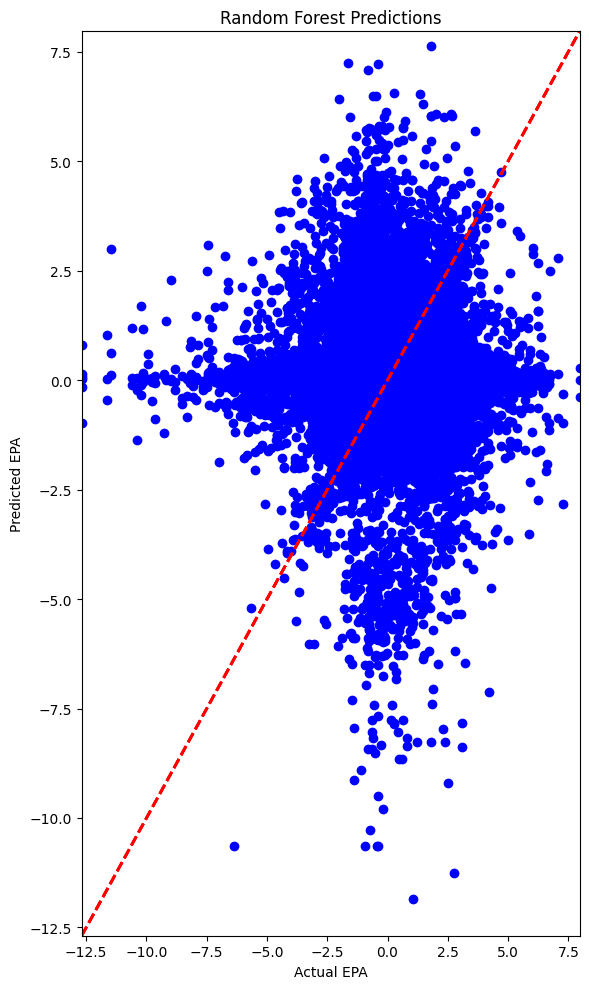

In [ ]:
# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Mean CV R² Score"])
print("\nModel Performance Metrics using Cross-Validation for R² Score:")
print(results_df)

# To demonstrate predictions and plot results, let's still split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Predict on the test set for final evaluation
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

# Plotting actual vs predicted for each model vertically with smaller size
plt.figure(figsize = (6, 10))  # Adjusted size for a more compact vertical layout

for i, (name, y_pred) in enumerate(predictions.items()):
    plt.subplot(3, 1, i + 1)  # 3 rows, 1 column
    plt.scatter(y_test, y_pred, color = 'blue')
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', color = 'red', lw = 2)  # Diagonal line
    plt.title(f'{name} Predictions')
    plt.xlabel('Actual EPA')
    plt.ylabel('Predicted EPA')
    plt.xlim(y_test.min(), y_test.max())
    plt.ylim(y_test.min(), y_test.max())

plt.tight_layout()
plt.show()

# Defensive Clusterization